# GeoMet Flotation Data: Cu, Fe and S vs Flotation Performance

**Question:** Do head-grade Cu, Fe and S relate to rougher flotation behaviour (`fr`, `xr`) and locked-cycle test Cu recovery (`LCT`)?

**Data:** Flotation assays from the [GeoMet dataset on Zenodo](https://zenodo.org/records/7051975). The analysis uses 53 samples and optionally integrates drillhole assays.

## Variable definitions

| Variable | Working definition | Status |
|---|---|---|
| `Cu ppm`, `Fe ppm`, `S ppm` | Flotation-sample assays, converted to wt% for interpretation | Treated as head assays |
| `LCT` | Locked-cycle test Cu recovery, fraction | Confirmed by dataset description |
| `fr` | Mass fraction of feed reporting to rougher concentrate | Confirmed |
| `xr` | Cu grade of rougher concentrate, fraction | Working assumption; verify against the source paper |

**Important:** `fr` is a mass fraction, not a recovery. The implied rougher Cu recovery is calculated as `fr * xr / feed_Cu_fraction`. This consistency check cannot independently confirm the definition of `xr`.

## Reproducibility
Place `flotation.csv` in `data/`. To run the drillhole integration section, also place `drillholes.csv` in `data/`. See the accompanying README for setup and data-source notes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.spatial import cKDTree

sns.set_theme(style="whitegrid")

DATA_DIR = Path("data")
DATA_PATH = DATA_DIR / "flotation.csv"
DRILLHOLE_PATH = DATA_DIR / "drillholes.csv"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    """Save a figure in a consistent format."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Missing {DATA_PATH}. Download flotation.csv and place it in data/. "
        "See README.md for instructions."
    )

## 1. Load and inspect

In [2]:
raw = pd.read_csv(DATA_PATH)
print(f"{raw.shape[0]} rows x {raw.shape[1]} columns")
raw.head()

53 rows x 26 columns


,HOLEID,X,Y,Z,fr,xr,LCT,Ag ppm,Al ppm,Au ppm,...,K ppm,Mg ppm,Mn ppm,Na ppm,P ppm,S ppm,Si ppm,Th ppm,Ti ppm,U ppm
0,1,552.477467,-532.30374,205.5292,0.283015,0.018674,0.878482,3.868453,52663.89,0.559473,...,22420.69,5597.62,4533.00,2545.81,460.00,2190.0,185170.63,3.00000,3279.92,10.313938
1,2,745.774899,-279.77297,283.2592,0.164382,0.032202,0.942708,1.163020,59961.45,0.145705,...,12681.64,21675.07,567.67,17661.13,460.00,2515.0,297536.61,32.56262,1725.74,31.213873
2,5,200.349851,-520.86427,315.4624,0.217624,0.031381,0.875660,4.438694,57708.76,0.317735,...,8069.68,11989.16,3502.83,472.30,814.66,4260.0,186907.60,3.00000,3739.87,19.530516
3,6,494.372077,-528.86816,311.2195,0.223851,0.022228,0.912880,2.720497,61648.61,0.455832,...,15200.58,15857.07,4735.52,6325.94,790.56,2710.0,185147.18,3.00000,4598.24,9.784736
4,6,500.224749,-513.62142,266.3491,0.200504,0.054880,0.937375,2.800237,33358.01,2.116526,...,4545.44,5405.55,981.06,14708.27,983.61,9830.0,128867.71,3.00000,2089.48,32.869081


## 2. Data quality

In [3]:
quality = pd.DataFrame({
    "missing": raw.isna().sum(),
    "share_at_column_min": raw.apply(lambda s: (s == s.min()).mean()),
})
print("Columns with missing values or >10% of rows sitting at the column minimum:")
display(quality[(quality.missing > 0) | (quality.share_at_column_min > 0.10)].round(2))

print(f"\nFully duplicated rows : {raw.duplicated().sum()}")
print(f"Unique drillholes     : {raw['HOLEID'].nunique()} (for {len(raw)} samples)")
print(f"Samples per hole      : min {raw.groupby('HOLEID').size().min()}, max {raw.groupby('HOLEID').size().max()}")

Columns with missing values or >10% of rows sitting at the column minimum:


,missing,share_at_column_min
LCT,1,0.02
Cl ppm,4,0.02
P ppm,0,0.11
Th ppm,0,0.53



Fully duplicated rows : 0
Unique drillholes     : 29 (for 53 samples)
Samples per hole      : min 1, max 4


Points to carry forward:

- `HOLEID` identifies a drillhole, not a sample. Several samples come from the same hole, so the 53 rows are not fully independent (see section 7).
- Only `LCT` (1 missing) and `Cl` (4 missing) have gaps. Neither is a focus variable beyond `LCT`; the `LCT` row is dropped pairwise in the correlations.
- Columns with a large share of values at their minimum look censored at a detection limit: 53% of `Th` values and 11% of `P` values sit at the column minimum. They are not used in this analysis.

## 3. Focus dataset: Cu, Fe, S and flotation variables

In [4]:
df = raw.copy()

# Convert to wt% so values are readable
for el in ["Cu", "Fe", "S"]:
    df[f"{el} %"] = df[f"{el} ppm"] / 1e4

df["S:Cu"] = df["S ppm"] / df["Cu ppm"]     # mass ratio
df["Fe:S"] = df["Fe ppm"] / df["S ppm"]

grades = ["Cu %", "Fe %", "S %"]
perf = ["fr", "xr", "LCT"]

summary = df[grades + ["S:Cu"] + perf].describe().T
summary["skew"] = df[grades + ["S:Cu"] + perf].skew()
display(summary.round(3))

,count,mean,std,min,25%,50%,75%,max,skew
Cu %,53.0,1.070,0.522,0.261,0.648,1.024,1.264,2.722,1.012
Fe %,53.0,27.498,11.323,2.694,22.735,27.399,33.102,55.861,0.022
S %,53.0,0.465,0.342,0.095,0.232,0.347,0.588,1.840,1.908
S:Cu,53.0,0.419,0.177,0.257,0.316,0.346,0.443,1.011,2.066
fr,53.0,0.248,0.051,0.164,0.217,0.235,0.270,0.383,0.910
xr,53.0,0.040,0.018,0.006,0.023,0.037,0.055,0.080,0.332
LCT,52.0,0.879,0.053,0.718,0.844,0.894,0.915,0.968,-0.816


## 4. Distributions

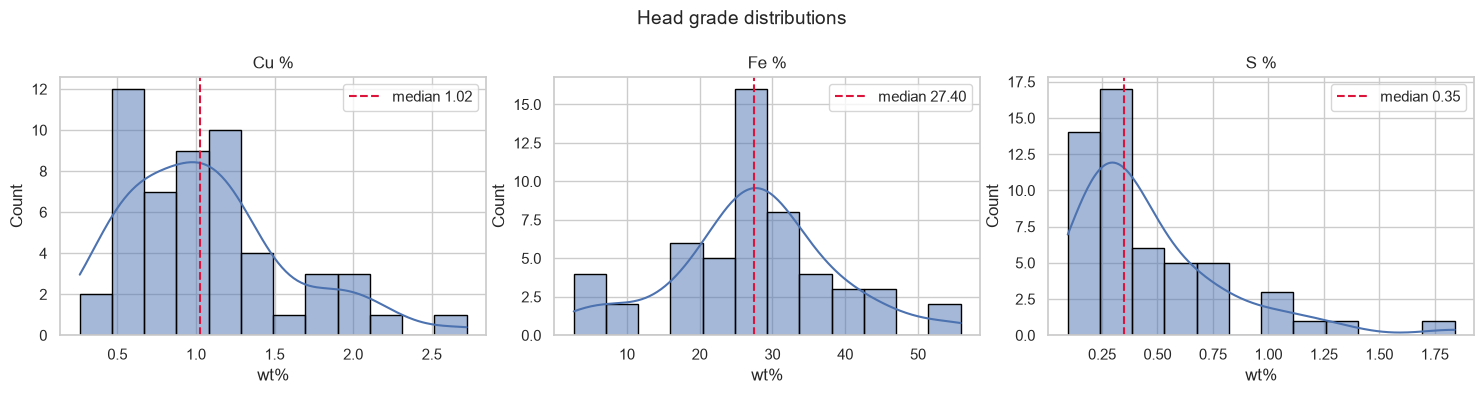

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, grades):
    sns.histplot(df[col], bins=12, kde=True, edgecolor="black", ax=ax)
    ax.axvline(df[col].median(), color="crimson", ls="--", label=f"median {df[col].median():.2f}")
    ax.set_title(col)
    ax.set_xlabel("wt%")
    ax.legend()
fig.suptitle("Head grade distributions", fontsize=14)
fig.tight_layout()
save(fig, "01_grade_distributions")
plt.show()

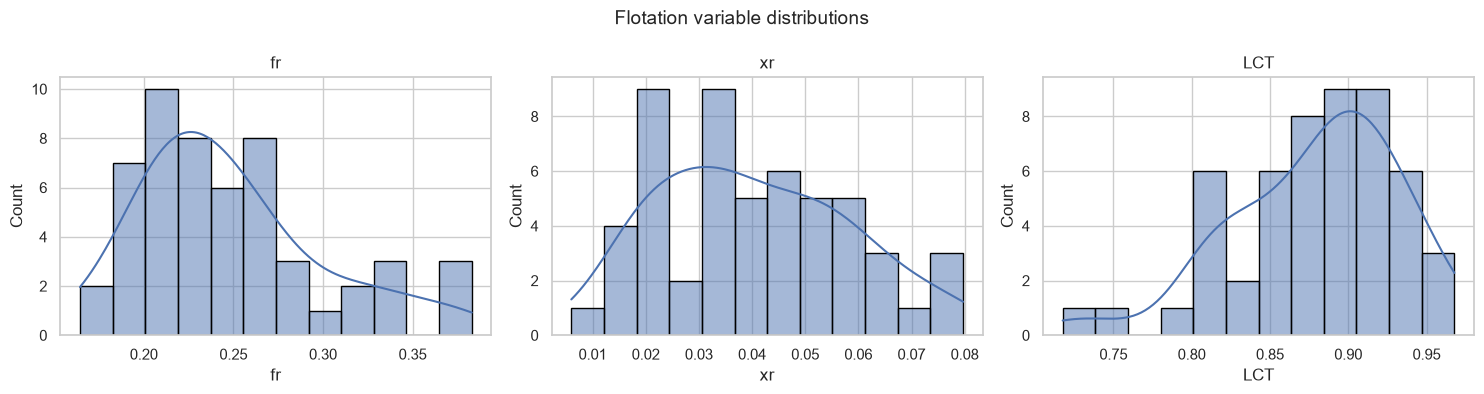

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, perf):
    sns.histplot(df[col], bins=12, kde=True, edgecolor="black", ax=ax)
    ax.set_title(col)
fig.suptitle("Flotation variable distributions", fontsize=14)
fig.tight_layout()
save(fig, "02_flotation_distributions")
plt.show()

### Interpreting the distributions

Use these plots to understand skew, spread and potential outliers, not to infer causes. A high proportion of values at a column minimum can indicate a detection-limit or censoring issue; confirm that interpretation against the dataset documentation before treating those values as true zeros.

## 5. Relationships between Cu, Fe, S and flotation performance

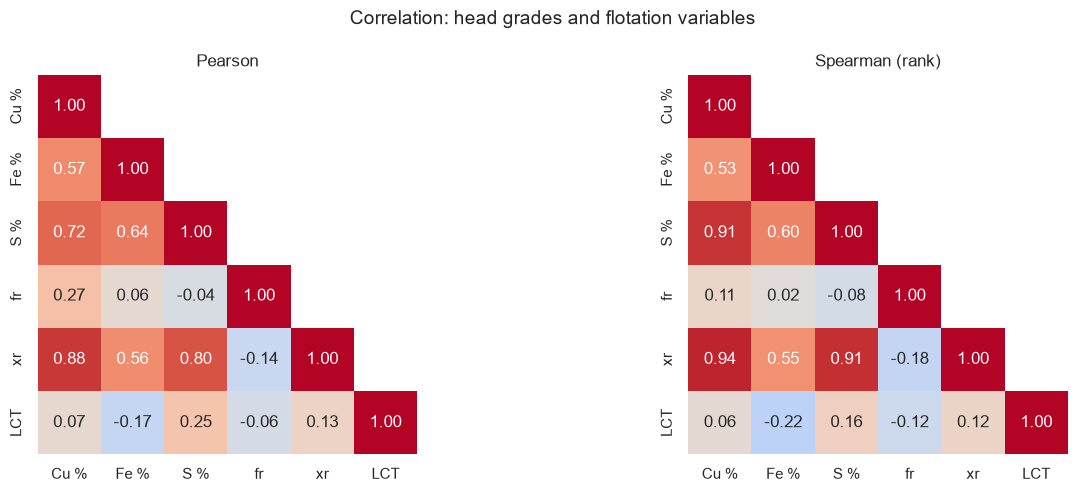

In [7]:
cols = grades + perf
pearson = df[cols].corr(method="pearson")
spearman = df[cols].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
mask = np.triu(np.ones_like(pearson, dtype=bool), k=1)
for ax, mat, title in zip(axes, [pearson, spearman], ["Pearson", "Spearman (rank)"]):
    sns.heatmap(mat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, square=True, cbar=False, ax=ax)
    ax.set_title(title)
    ax.grid(False)
fig.suptitle("Correlation: head grades and flotation variables", fontsize=14)
fig.tight_layout()
save(fig, "03_correlations")
plt.show()

In [8]:
# Exploratory tests: each grade against each flotation variable.
# Adjust for the nine comparisons using Benjamini-Hochberg false discovery rate (FDR).
from statsmodels.stats.multitest import multipletests

rows = []
for g in grades:
    for p in perf:
        sub = df[[g, p]].dropna()
        if len(sub) < 3 or sub[g].nunique() < 2 or sub[p].nunique() < 2:
            r, pval, rho, pval_s = np.nan, np.nan, np.nan, np.nan
        else:
            r, pval = stats.pearsonr(sub[g], sub[p])
            rho, pval_s = stats.spearmanr(sub[g], sub[p])
        rows.append({
            "grade": g, "flotation": p, "n": len(sub),
            "pearson_r": r, "p_pearson": pval,
            "spearman_rho": rho, "p_spearman": pval_s
        })

tests = pd.DataFrame(rows)
for p_col, adjusted_col in [("p_pearson", "p_pearson_fdr"),
                             ("p_spearman", "p_spearman_fdr")]:
    valid = tests[p_col].notna()
    tests[adjusted_col] = np.nan
    if valid.any():
        tests.loc[valid, adjusted_col] = multipletests(
            tests.loc[valid, p_col], method="fdr_bh"
        )[1]

display(tests.round(3))
print("Benjamini-Hochberg FDR adjustment is applied separately to Pearson and Spearman "
      "p-values across the nine grade-versus-performance tests.")

,grade,flotation,n,pearson_r,p_pearson,spearman_rho,p_spearman,p_pearson_fdr,p_spearman_fdr
0,Cu %,fr,53,0.274,0.047,0.106,0.449,0.105,0.673
1,Cu %,xr,53,0.885,0.000,0.938,0.000,0.000,0.000
2,Cu %,LCT,52,0.072,0.614,0.062,0.661,0.729,0.743
3,Fe %,fr,53,0.064,0.648,0.016,0.910,0.729,0.910
4,Fe %,xr,53,0.560,0.000,0.545,0.000,0.000,0.000
5,Fe %,LCT,52,-0.167,0.237,-0.223,0.112,0.356,0.252
6,S %,fr,53,-0.045,0.750,-0.076,0.587,0.750,0.743
7,S %,xr,53,0.796,0.000,0.908,0.000,0.000,0.000
8,S %,LCT,52,0.254,0.069,0.158,0.264,0.125,0.474


Benjamini-Hochberg FDR adjustment is applied separately to Pearson and Spearman p-values across the nine grade-versus-performance tests.


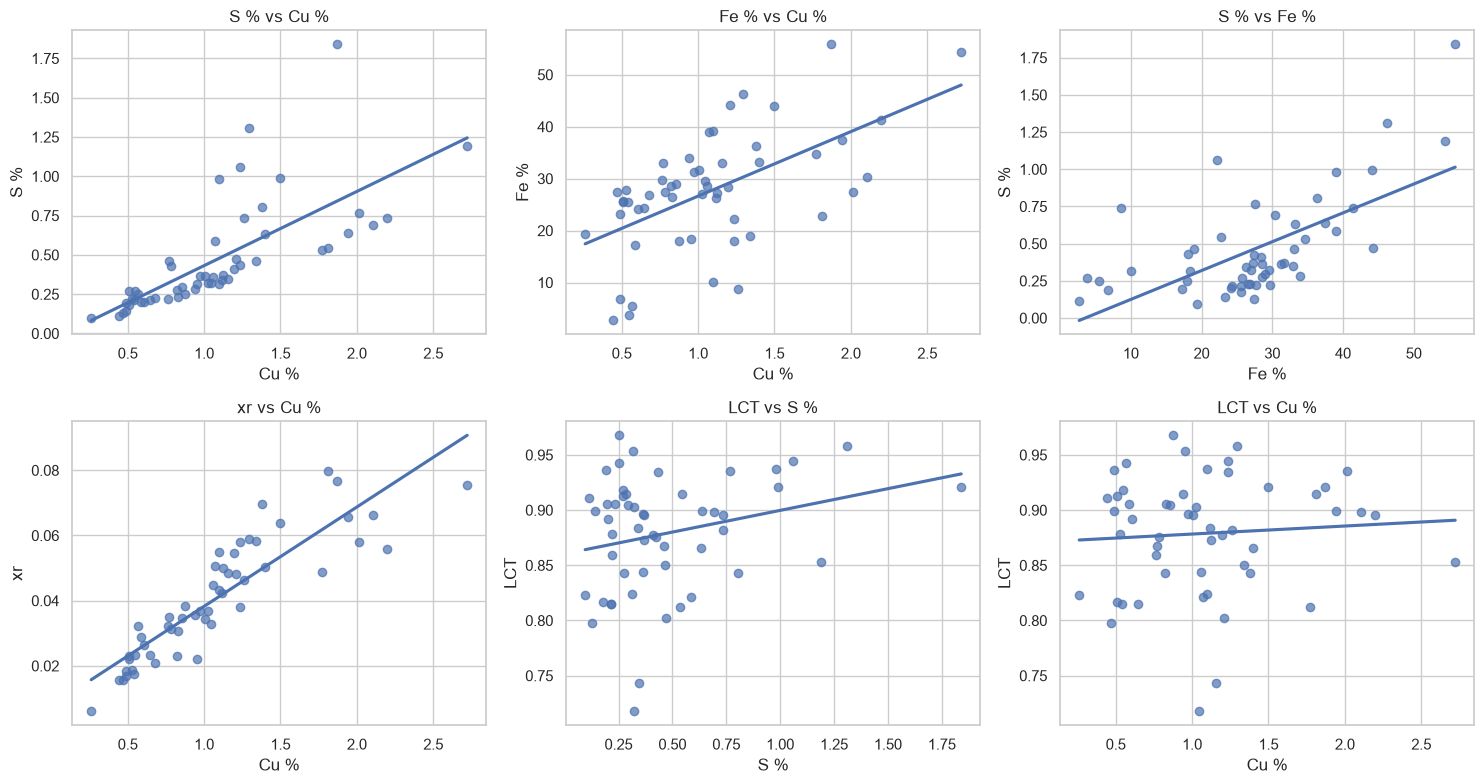

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

pairs = [("Cu %", "S %"), ("Cu %", "Fe %"), ("Fe %", "S %"),
         ("Cu %", "xr"), ("S %", "LCT"), ("Cu %", "LCT")]
for ax, (x, y) in zip(axes.ravel(), pairs):
    sns.regplot(data=df, x=x, y=y, ci=None, scatter_kws={"alpha": 0.7}, ax=ax)
    ax.set_title(f"{y} vs {x}")
fig.tight_layout()
save(fig, "04_key_scatterplots")
plt.show()

## 6. Mass-balance consistency check for `fr` and `xr`

`fr` is the **mass fraction** of feed reporting to rougher concentrate. Under the working assumption that `xr` is the rougher-concentrate Cu grade (both fractions), the implied rougher Cu recovery is:

\[
R_{rougher} = 
rac{f_r 	imes x_r}{	ext{feed Cu grade as a mass fraction}}
\]

This is a consistency check, not a substitute for source documentation or a measured recovery value.

,implied_rougher_Cu_recovery
count,53.000
mean,0.920
std,0.049
min,0.822
25%,0.883
50%,0.916
75%,0.954
max,1.023


Valid calculations: 53 of 53
Implied rougher Cu recovery >100%: 3 of 53
Values above 100% are flags for investigation, not automatically measurement errors.


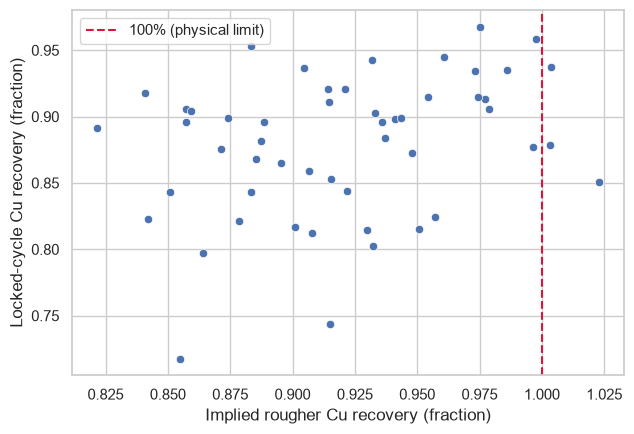

In [10]:
# fr = mass fraction to rougher concentrate.
# xr is assumed to be rougher-concentrate Cu grade; both are fractions.
# Convert feed Cu from ppm to a mass fraction (ppm / 1,000,000).
feed_cu_fraction = df["Cu ppm"] / 1e6
valid_balance = (df["fr"].notna() & df["xr"].notna() &
                 feed_cu_fraction.notna() & (feed_cu_fraction > 0))
df["R_rougher_implied"] = np.nan
df.loc[valid_balance, "R_rougher_implied"] = (
    df.loc[valid_balance, "fr"] * df.loc[valid_balance, "xr"] /
    feed_cu_fraction.loc[valid_balance]
)

display(df["R_rougher_implied"].describe().to_frame(
    "implied_rougher_Cu_recovery"
).round(3))
n_valid = int(df["R_rougher_implied"].notna().sum())
n_over = int((df["R_rougher_implied"] > 1).sum())
print(f"Valid calculations: {n_valid} of {len(df)}")
print(f"Implied rougher Cu recovery >100%: {n_over} of {n_valid}")
print("Values above 100% are flags for investigation, not automatically measurement errors.")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
plot_df = df.dropna(subset=["R_rougher_implied", "LCT"])
sns.scatterplot(data=plot_df, x="R_rougher_implied", y="LCT", ax=ax)
ax.axvline(1.0, color="crimson", ls="--", label="100% (physical limit)")
ax.set_xlabel("Implied rougher Cu recovery (fraction)")
ax.set_ylabel("Locked-cycle Cu recovery (fraction)")
ax.legend()
fig.tight_layout()
save(fig, "05_implied_rougher_recovery")
plt.show()

**Interpretation:** Compare the calculated range with the physical limit of 100%. Values above 1 may reflect assay/test uncertainty, mismatched definitions, unit assumptions or data-quality issues. Do not conclude that `xr` is confirmed from this check alone; its definition remains a working assumption until verified against the source paper.

## 7. Robustness: repeated samples per drillhole

In [11]:
# Average samples within each hole so each hole counts once (n ~ 29)
by_hole = df.groupby("HOLEID")[grades + perf].mean()

rows = []
for g in grades:
    for p in perf:
        sub = by_hole[[g, p]].dropna()
        rho, pval = stats.spearmanr(sub[g], sub[p])
        rows.append({"grade": g, "flotation": p, "n_holes": len(sub),
                     "spearman_rho": rho, "p": pval})
display(pd.DataFrame(rows).round(3))

,grade,flotation,n_holes,spearman_rho,p
0,Cu %,fr,29,0.070,0.717
1,Cu %,xr,29,0.872,0.000
2,Cu %,LCT,29,-0.043,0.825
3,Fe %,fr,29,-0.009,0.964
4,Fe %,xr,29,0.490,0.007
5,Fe %,LCT,29,-0.317,0.094
6,S %,fr,29,-0.173,0.370
7,S %,xr,29,0.831,0.000
8,S %,LCT,29,0.090,0.644


## 8. Joining the drillhole assays

In [12]:
if not DRILLHOLE_PATH.exists():
    print("Optional drillhole integration skipped: data/drillholes.csv was not found.")
    dh = None
else:
    dh = pd.read_csv(DRILLHOLE_PATH)
    required_dh = {"HOLEID", "X", "Y", "Z"}
    missing_dh = required_dh - set(dh.columns)
    if missing_dh:
        raise ValueError(f"Required columns missing from drillholes.csv: {sorted(missing_dh)}")
    print(f"drillholes.csv: {dh.shape[0]} assay rows, {dh['HOLEID'].nunique()} holes")
    print("Elements in drillholes but not in flotation:", sorted(set(dh.columns) - set(raw.columns)))
    missing_holes = sorted(set(raw["HOLEID"]) - set(dh["HOLEID"]))
    print("Flotation holes with no drillhole assays:", missing_holes)

drillholes.csv: 2000 assay rows, 119 holes
Elements in drillholes but not in flotation: ['Pb ppm']
Flotation holes with no drillhole assays: [132, 133]


`HOLEID` repeats in both tables, so merging on that field alone can multiply rows. When `drillholes.csv` is available, each flotation sample is matched to the nearest assay point within the same hole using 3D coordinates. Match distance is retained and a configurable threshold is applied. Samples with no same-hole assay or invalid coordinates remain visible as unmatched rather than silently disappearing.

In [13]:
# Nearest-neighbour matching within each hole, preserving every flotation row.
if dh is not None:
    COORDS = ["X", "Y", "Z"]
    MAX_DIST = 25  # metres; matches farther away are flagged as unmatched

    dh_work = dh.copy()
    raw_work = raw.copy()
    for col in COORDS:
        dh_work[col] = pd.to_numeric(dh_work[col], errors="coerce")
        raw_work[col] = pd.to_numeric(raw_work[col], errors="coerce")

    matched_parts = []
    for hole, fl_rows in raw_work.groupby("HOLEID", sort=False):
        pool = dh_work.loc[dh_work["HOLEID"] == hole].dropna(subset=COORDS)
        fl_valid = fl_rows.dropna(subset=COORDS)
        if pool.empty or fl_valid.empty:
            continue

        tree = cKDTree(pool[COORDS].to_numpy(dtype=float))
        dist, idx = tree.query(fl_valid[COORDS].to_numpy(dtype=float))
        nearest = pool.iloc[idx].drop(columns=["HOLEID"] + COORDS).add_suffix("_dh")
        nearest.index = fl_valid.index
        nearest["match_dist"] = dist
        matched_parts.append(nearest)

    if matched_parts:
        nearest_all = pd.concat(matched_parts).sort_index()
        assert nearest_all.index.is_unique, "Nearest-neighbour result duplicated flotation rows"
        joined = raw.join(nearest_all, how="left")
    else:
        joined = raw.copy()
        joined["match_dist"] = np.nan

    print(f"Flotation samples total: {len(raw)}")
    print(f"Samples with a same-hole nearest assay: {joined['match_dist'].notna().sum()}")
    print(f"Unmatched (missing hole or invalid coordinates): {joined['match_dist'].isna().sum()}")
    print(f"Matches farther than {MAX_DIST} m: {(joined['match_dist'] > MAX_DIST).sum()}")
    display(joined["match_dist"].describe().to_frame("match_distance_m").round(2))

    joined["match_status"] = np.select(
        [joined["match_dist"].isna(), joined["match_dist"] > MAX_DIST],
        ["unmatched", "over_threshold"],
        default="accepted"
    )
    joined_accepted = joined.loc[joined["match_status"] == "accepted"].copy()
    print(f"Accepted matches within {MAX_DIST} m: {len(joined_accepted)}")
else:
    joined = None
    joined_accepted = None

Flotation samples total: 53
Samples with a same-hole nearest assay: 51
Unmatched (missing hole or invalid coordinates): 2
Matches farther than 25 m: 1


,match_distance_m
count,51.00
mean,6.98
std,7.81
min,0.07
25%,1.97
50%,4.36
75%,11.75
max,49.95


Accepted matches within 25 m: 50


C:\Users\Menzi\AppData\Local\Temp\ipykernel_17724\3775669753.py:20: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


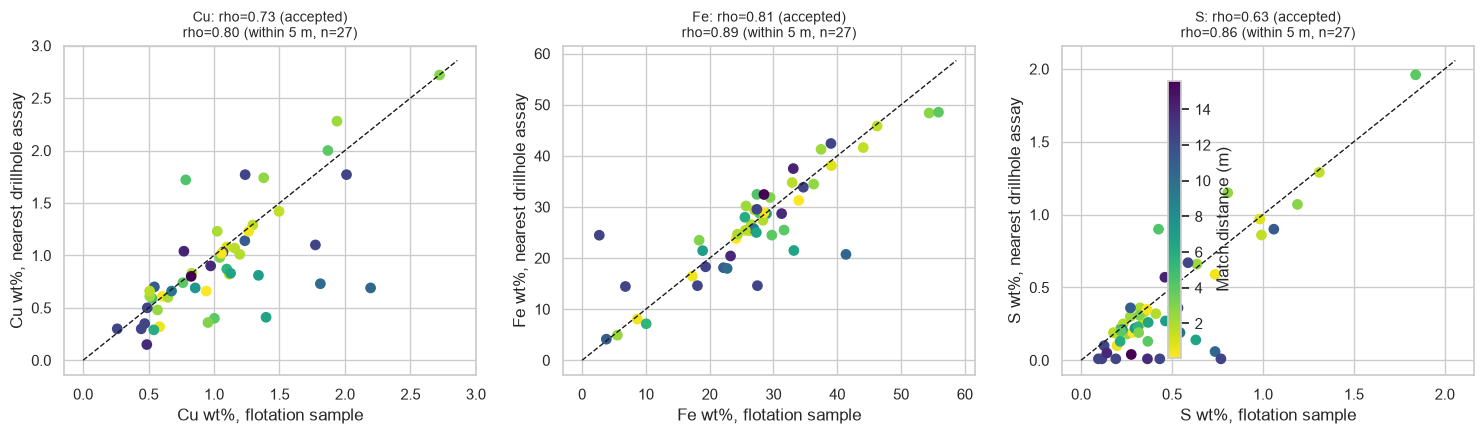

In [14]:
if joined_accepted is not None and not joined_accepted.empty:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
    for ax, el in zip(axes, ["Cu", "Fe", "S"]):
        x = joined_accepted[f"{el} ppm"] / 1e4
        y = joined_accepted[f"{el} ppm_dh"] / 1e4
        valid = x.notna() & y.notna()
        x, y = x[valid], y[valid]
        distances = joined_accepted.loc[valid, "match_dist"]
        sc = ax.scatter(x, y, c=distances, cmap="viridis_r", s=45)
        lim = [0, max(x.max(), y.max()) * 1.05] if len(x) else [0, 1]
        ax.plot(lim, lim, "k--", lw=1)
        rho_all = stats.spearmanr(x, y).statistic if len(x) >= 3 else np.nan
        near = distances <= 5
        rho_near = stats.spearmanr(x[near], y[near]).statistic if near.sum() >= 3 else np.nan
        ax.set_title(f"{el}: rho={rho_all:.2f} (accepted)\nrho={rho_near:.2f} (within 5 m, n={near.sum()})",
                     fontsize=10)
        ax.set_xlabel(f"{el} wt%, flotation sample")
        ax.set_ylabel(f"{el} wt%, nearest drillhole assay")
    fig.colorbar(sc, ax=axes, label="Match distance (m)", shrink=0.8)
    fig.tight_layout()
    save(fig, "06_flotation_vs_drillhole_assays")
    plt.show()
else:
    print("No accepted drillhole matches available for comparison.")

In [15]:
if joined_accepted is not None and not joined_accepted.empty:
    # Pb is available only in drillholes.csv; X/Y/Z are spatial coordinates.
    new_vars = [v for v in ["Pb ppm_dh", "Cu ppm_dh", "Fe ppm_dh", "S ppm_dh", "X", "Y", "Z"]
                if v in joined_accepted.columns]
    rows = []
    for v in new_vars:
        sub = joined_accepted[[v, "LCT"]].dropna()
        if len(sub) < 3 or sub[v].nunique() < 2 or sub["LCT"].nunique() < 2:
            rho, pval = np.nan, np.nan
        else:
            rho, pval = stats.spearmanr(sub[v], sub["LCT"])
        rows.append({"variable": v, "n": len(sub), "spearman_rho": rho, "p_unadjusted": pval})

    new_tests = pd.DataFrame(rows)
    valid = new_tests["p_unadjusted"].notna()
    new_tests["p_bonferroni"] = np.nan
    new_tests["p_fdr"] = np.nan
    if valid.any():
        new_tests.loc[valid, "p_bonferroni"] = multipletests(
            new_tests.loc[valid, "p_unadjusted"], method="bonferroni"
        )[1]
        new_tests.loc[valid, "p_fdr"] = multipletests(
            new_tests.loc[valid, "p_unadjusted"], method="fdr_bh"
        )[1]
    display(new_tests.round(3))
else:
    print("Drillhole-LCT exploratory tests skipped because no accepted matches are available.")

,variable,n,spearman_rho,p_unadjusted,p_bonferroni,p_fdr
0,Pb ppm_dh,49,0.247,0.087,0.608,0.177
1,Cu ppm_dh,49,0.075,0.607,1.000,0.849
2,Fe ppm_dh,49,-0.237,0.101,0.707,0.177
3,S ppm_dh,49,-0.013,0.929,1.000,0.983
4,X,49,0.322,0.024,0.167,0.167
5,Y,49,-0.242,0.094,0.657,0.177
6,Z,49,-0.003,0.983,1.000,0.983


### Interpreting the drillhole join

- Agreement between point assays and flotation-sample assays is informative, but exact agreement is not expected: composites and point samples represent different sampling supports.
- Compare the flotation-sample grade distribution with the drillhole population before generalising to the deposit.
- Drillhole integration adds spatial context; it does not establish that location or any added element causes recovery differences.
- Treat spatial and assay associations as exploratory, especially with a small sample and repeated samples from the same drillhole. Consider effect sizes, adjusted p-values and independent validation together.

## 9. Conclusions

Use the tables and figures above to report observed effect sizes, sample sizes and adjusted p-values. Separate descriptive patterns from inferential claims.

### Interpretation guardrails

- Correlation is not causation. Grade associations can reflect shared geology, mineralogy, compositional effects or sample selection.
- `fr` is the mass fraction reporting to rougher concentrate; it is not a recovery.
- `fr * xr / feed_Cu_fraction` is an implied rougher Cu recovery only under the working definition of `xr` as rougher-concentrate Cu grade.
- The drillhole join is approximate: it matches a flotation sample to a nearby point assay, not necessarily the original interval or composite.
- A non-significant result does not prove no relationship exists; the dataset is small and samples are clustered by drillhole.

## 10. Limitations

- **Small sample:** 53 flotation rows provide limited statistical power.
- **Clustered observations:** multiple samples come from the same drillhole. Hole-level averaging is a sensitivity check, not a full spatial model.
- **Exploratory tests:** multiple comparisons require adjustment; interpret adjusted p-values alongside effect sizes.
- **Assay detection limits:** values concentrated at column minima may be censored and need confirmation from dataset documentation.
- **Compositional data:** assays are components of a whole, so closure effects can induce or distort correlations.
- **Join assumptions:** nearest-point matching within 25 m is a proxy for interval correspondence; unmatched samples should remain explicitly reported.
- **Variable definition:** `xr` remains a working assumption until checked against the source paper.
- **No predictive validation:** this notebook explores relationships; it does not demonstrate a validated predictive model.

## 11. Recommended next steps

1. Verify the definition and units of `xr` against the source paper.
2. Review detection-limit and sampling documentation.
3. Test matching-distance thresholds (for example, 5 m, 10 m and 25 m).
4. If modelling is pursued, use drillhole-grouped cross-validation to reduce leakage between samples from the same hole.
5. Add mineralogy, liberation, grind size and test-condition variables if available; these may be more informative for recovery than head grade alone.